In [1]:
from hapi import *
import numpy as np
import matplotlib.pyplot as plt

HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      

In [3]:
db_begin("data")
fetch("CO2", 2, 1, 2200, 2400)

Using data


Data is fetched from http://hitran.org

BEGIN DOWNLOAD: CO2
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/

In [4]:
nu, coef = absorptionCoefficient_Voigt(
    SourceTables="CO2",
    OmegaRange=[2200, 2400],
    HITRAN_units=False
)

{'air': 1.0}
7.651160 seconds elapsed for abscoef; nlines = 16405


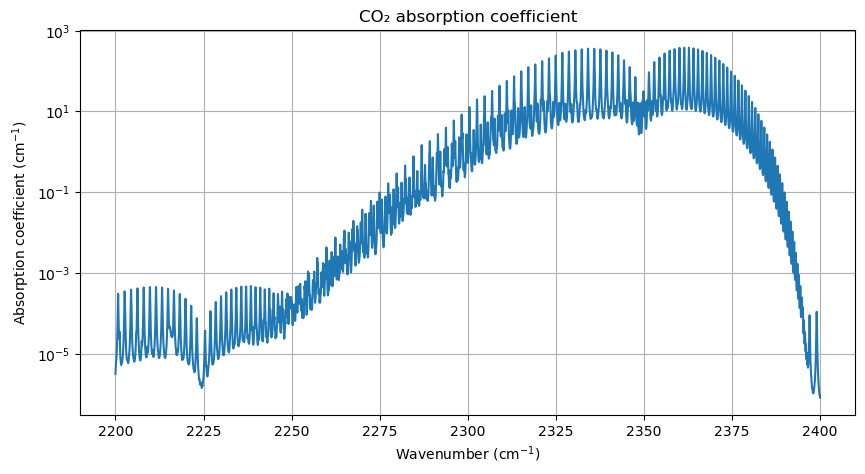

In [6]:
plt.figure(figsize=(10, 5))

plt.semilogy(nu, coef)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Absorption coefficient (cm$^{-1}$)")
plt.title("CO₂ absorption coefficient")

plt.grid()

plt.show()

In [9]:
nu, coef = absorptionCoefficient_Lorentz(
    SourceTables='CO2',
    HITRAN_units=False
)

nu, trans = transmittanceSpectrum(nu, coef)

{'air': 1.0}
4.577757 seconds elapsed for abscoef; nlines = 16405


In [16]:
nu1, coef1 = absorptionCoefficient_Voigt(
    SourceTables="CO2",
    OmegaRange=[2200, 2400],
    HITRAN_units=False,
    Environment={
        "T": 296,
        "p": 1.0
    }
)
nu2, coef2 = absorptionCoefficient_Voigt(
    SourceTables="CO2",
    OmegaRange=[2200, 2400],
    HITRAN_units=False,
    Environment={
        "T": 250,
        "p": 0.5
    }
)

{'air': 1.0}
7.847950 seconds elapsed for abscoef; nlines = 16405
{'air': 1.0}
5.576006 seconds elapsed for abscoef; nlines = 16405


In [18]:
L1 = 1.0
L2 = 1.0
nu1, trans1 = transmittanceSpectrum(nu1, coef1)

nu2, trans2 = transmittanceSpectrum(nu2, coef2)

total_transmission = trans1 * trans2

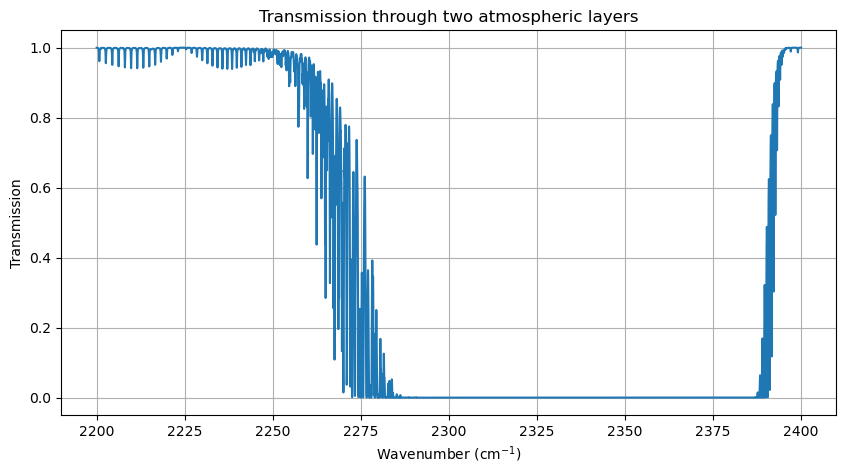

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(nu1, total_transmission)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Transmission")

plt.title("Transmission through two atmospheric layers")

#plt.ylim(0, 1.05)

plt.grid()

plt.show()

In [24]:
temperatures = [296, 285, 270, 255, 240]
pressures    = [1.0, 0.8, 0.6, 0.4, 0.2]
total_transmission = None
for T, P in zip(temperatures, pressures):

    nu, coef = absorptionCoefficient_Voigt(
        SourceTables="CO2",
        OmegaRange=[2200, 2400],
        HITRAN_units=False,
        Environment={
            "T": T,
            "p": P
        }
    )

    nu, trans = transmittanceSpectrum(nu, coef)

    if total_transmission is None:
        total_transmission = trans
    else:
        total_transmission = total_transmission * trans

{'air': 1.0}
7.462195 seconds elapsed for abscoef; nlines = 16405
{'air': 1.0}
7.523548 seconds elapsed for abscoef; nlines = 16405
{'air': 1.0}
7.245099 seconds elapsed for abscoef; nlines = 16405
{'air': 1.0}
9.429717 seconds elapsed for abscoef; nlines = 16405
{'air': 1.0}
10.072034 seconds elapsed for abscoef; nlines = 16405


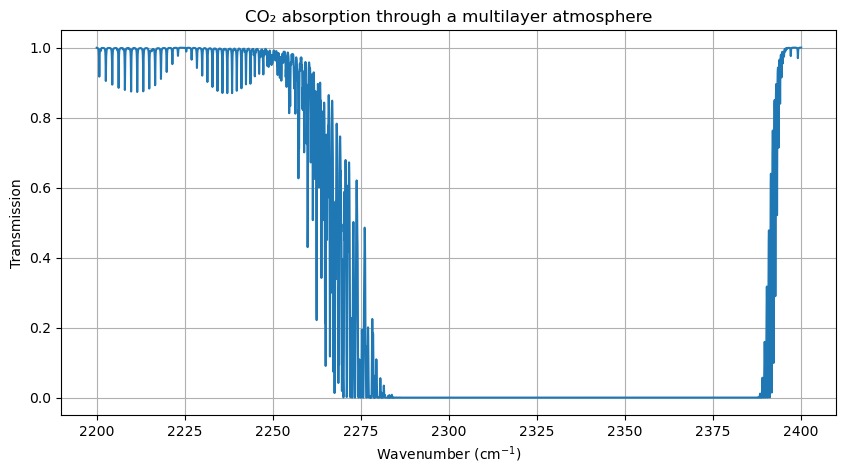

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(nu, total_transmission)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Transmission")

plt.title("CO₂ absorption through a multilayer atmosphere")

#plt.ylim(0, 1.05)

plt.grid()

plt.show()